# Deuxième partie — Exercice 1 : prévision électrique

**Objectif :** prédire la puissance moyenne de l'heure suivante à partir des
24 dernières heures observées avec un `EnergyTransformer`.
Cette solution reprend les consignes du cours et s'exécute indépendamment.

Données : [Individual Household Electric Power Consumption, UCI](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption).
Décompresser `household_power_consumption.txt` à la racine du dépôt avant l'exécution.
Le fichier reste local. Aucun téléchargement automatique ni donnée artificielle ne remplace ce fichier.

La variable `Global_active_power` est une puissance en **kW**. Les données sont
agrégées par heure ; une heure avec moins de 45 mesures valides reste manquante.
La lecture utilise la bibliothèque standard pour ne pas ajouter de dépendance pandas.

In [1]:
import csv
from copy import deepcopy
from datetime import datetime
import math
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)
# Deux threads suffisent pour ces petits modèles et limitent le surcoût CPU.
torch.set_num_threads(2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RACINE = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file()),
    None,
)
if RACINE is None:
    raise FileNotFoundError("Ouvrir ce notebook depuis le dépôt Architecture-Transformer.")
print("Périphérique :", device)

CHEMIN_DONNEES = RACINE / "household_power_consumption.txt"
FENETRE = 24
BATCH_SIZE = 64
MAX_EPOCHS = 20
PATIENCE = 4
if not CHEMIN_DONNEES.is_file():
    raise FileNotFoundError(f"Télécharger les données UCI et décompresser : {CHEMIN_DONNEES}")

Périphérique : cpu


## 1. Préparation sans fuite de données

On conserve une grille horaire complète : retirer une heure manquante avant de
créer les fenêtres ferait passer deux heures éloignées pour des heures consécutives.
Le découpage 70 % / 15 % / 15 % est chronologique. La moyenne et l'écart type
sont calculés sur l'entraînement uniquement. Une fenêtre est affectée à un jeu
selon l'heure de sa **cible** ; son contexte peut contenir des observations du jeu précédent.

In [2]:
def charger_serie_horaire(chemin):
    agregats = {}
    with chemin.open(encoding="utf-8", newline="") as fichier:
        for ligne in csv.DictReader(fichier, delimiter=";"):
            cle = ligne["Date"] + " " + ligne["Time"][:2]
            total_compte = agregats.setdefault(cle, [0.0, 0])
            try:
                valeur = float(ligne["Global_active_power"])
            except (ValueError, TypeError):
                continue
            if math.isfinite(valeur):
                total_compte[0] += valeur
                total_compte[1] += 1
    if not agregats:
        raise ValueError("Le fichier ne contient aucune mesure.")
    dates_lues = np.array([
        np.datetime64(datetime.strptime(cle, "%d/%m/%Y %H"), "h")
        for cle in agregats
    ])
    dates = np.arange(dates_lues.min(), dates_lues.max() + np.timedelta64(1, "h"),
                      np.timedelta64(1, "h"))
    serie = np.full(len(dates), np.nan)
    indices = (dates_lues - dates[0]).astype("timedelta64[h]").astype(int)
    for indice, (total, compte) in zip(indices, agregats.values()):
        if compte >= 45:
            serie[indice] = total / compte
    return dates, serie

dates, serie = charger_serie_horaire(CHEMIN_DONNEES)
fin_train, fin_val = int(0.70 * len(serie)), int(0.85 * len(serie))
moyenne = np.nanmean(serie[:fin_train])
ecart_type = np.nanstd(serie[:fin_train], ddof=1)
assert np.isfinite(moyenne) and np.isfinite(ecart_type) and ecart_type > 0
valeurs = (serie - moyenne) / ecart_type

fenetres = np.lib.stride_tricks.sliding_window_view(valeurs, FENETRE + 1)
valides = np.isfinite(fenetres).all(axis=1)
indices_cibles = np.arange(FENETRE, len(serie))[valides]
X = torch.tensor(fenetres[valides, :-1].copy(), dtype=torch.float32).unsqueeze(-1)
y = torch.tensor(fenetres[valides, -1].copy(), dtype=torch.float32).unsqueeze(-1)
masques = {
    "train": indices_cibles < fin_train,
    "validation": (indices_cibles >= fin_train) & (indices_cibles < fin_val),
    "test": indices_cibles >= fin_val,
}
loaders = {}
for nom, masque in masques.items():
    assert masque.any(), f"Aucune fenêtre dans {nom}."
    loaders[nom] = DataLoader(
        TensorDataset(X[masque], y[masque]), batch_size=BATCH_SIZE,
        shuffle=(nom == "train"), generator=torch.Generator().manual_seed(42),
    )
assert X.shape[1:] == (24, 1) and y.shape[1:] == (1,)
assert np.all(np.diff(dates) == np.timedelta64(1, "h"))
assert abs(np.nanmean(valeurs[:fin_train])) < 1e-10
assert np.isclose(np.nanstd(valeurs[:fin_train], ddof=1), 1.0)
print(f"{len(serie):,} heures, dont {np.isnan(serie).sum():,} heures insuffisamment renseignées")
print({nom: len(loader.dataset) for nom, loader in loaders.items()})
print(f"Statistiques train : moyenne={moyenne:.4f} kW ; écart type={ecart_type:.4f} kW")

34,589 heures, dont 438 heures insuffisamment renseignées
{'train': 23805, 'validation': 5054, 'test': 4932}
Statistiques train : moyenne=1.0865 kW ; écart type=0.9287 kW


## 2. EnergyTransformer

Projection `1 → 32`, positions apprises sur 24 heures, deux couches d'encodeur
(`d_model=32`, `nhead=4`, `dim_feedforward=128`, `dropout=0.1`), puis projection
`32 → 1` de la dernière représentation. L'encodeur peut lire les 24 observations :
elles sont toutes antérieures à la cible, donc aucun masque causal n'est nécessaire.

In [3]:
class EnergyTransformer(nn.Module):
    def __init__(self, longueur=24):
        super().__init__()
        self.projection = nn.Linear(1, 32)
        self.positions = nn.Embedding(longueur, 32)
        couche = nn.TransformerEncoderLayer(
            d_model=32, nhead=4, dim_feedforward=128,
            dropout=0.1, batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=2)
        # Initialisations indépendantes des couches clonées par TransformerEncoder.
        for bloc in self.encodeur.layers:
            for poids in (
                bloc.self_attn.in_proj_weight, bloc.self_attn.out_proj.weight,
                bloc.linear1.weight, bloc.linear2.weight,
            ):
                nn.init.xavier_uniform_(poids)
        self.sortie = nn.Linear(32, 1)

    def forward(self, x):
        positions = torch.arange(x.size(1), device=x.device)
        x = self.projection(x) + self.positions(positions).unsqueeze(0)
        return self.sortie(self.encodeur(x)[:, -1, :])

modele = EnergyTransformer(FENETRE).to(device)
with torch.no_grad():
    assert modele(X[:2].to(device)).shape == (2, 1)
print(f"{sum(p.numel() for p in modele.parameters()):,} paramètres")

26,273 paramètres


## 3. Entraînement et choix du modèle

Adam (`lr=0.001`), perte MSE, au maximum 20 époques. L'arrêt anticipé attend quatre
époques sans amélioration. Chaque perte moyenne est pondérée par le nombre
d'exemples ; le dernier petit batch ne reçoit pas un poids excessif.
Le test n'intervient pas dans le choix des poids.

Époque  1 | train=0.47346 | validation=0.40751


Époque  2 | train=0.43123 | validation=0.38856


Époque  3 | train=0.42645 | validation=0.38580


Époque  4 | train=0.42196 | validation=0.38376


Époque  5 | train=0.41720 | validation=0.40741


Époque  6 | train=0.41673 | validation=0.39972


... (8 outputs left out)

Époque 15 | train=0.40219 | validation=0.38095


Époque 16 | train=0.40099 | validation=0.37716


Époque 17 | train=0.40146 | validation=0.37381


Arrêt anticipé.
Poids restaurés : époque 13


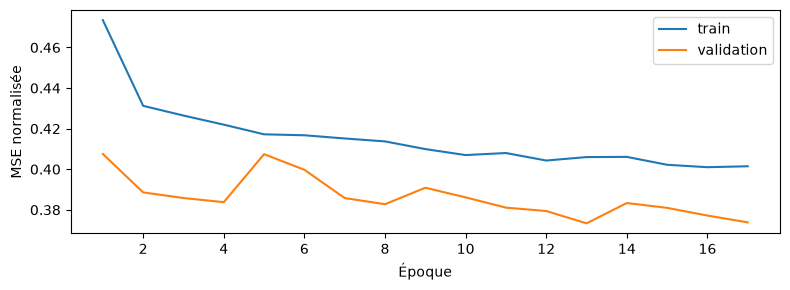

In [4]:
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.001)
critere = nn.MSELoss()

def entrainer_epoque():
    modele.train()
    total = 0.0
    for xb, yb in loaders["train"]:
        xb, yb = xb.to(device), yb.to(device)
        optimiseur.zero_grad(set_to_none=True)
        perte = critere(modele(xb), yb)
        assert torch.isfinite(perte)
        perte.backward()
        optimiseur.step()
        total += perte.item() * len(xb)
    return total / len(loaders["train"].dataset)

@torch.no_grad()
def perte_validation():
    modele.eval()
    total = 0.0
    for xb, yb in loaders["validation"]:
        xb, yb = xb.to(device), yb.to(device)
        total += critere(modele(xb), yb).item() * len(xb)
    return total / len(loaders["validation"].dataset)

historique = {"train": [], "validation": []}
meilleure_perte, meilleure_epoque, attente = float("inf"), 0, 0
meilleurs_poids = None
for epoque in range(1, MAX_EPOCHS + 1):
    train_loss = entrainer_epoque()
    val_loss = perte_validation()
    historique["train"].append(train_loss)
    historique["validation"].append(val_loss)
    print(f"Époque {epoque:2d} | train={train_loss:.5f} | validation={val_loss:.5f}", flush=True)
    if val_loss < meilleure_perte:
        meilleure_perte, meilleure_epoque = val_loss, epoque
        meilleurs_poids = deepcopy(modele.state_dict())
        attente = 0
    else:
        attente += 1
        if attente >= PATIENCE:
            print("Arrêt anticipé.")
            break
modele.load_state_dict(meilleurs_poids)
modele.eval()
print("Poids restaurés : époque", meilleure_epoque)
plt.figure(figsize=(8, 3))
for nom, pertes in historique.items():
    plt.plot(range(1, len(pertes) + 1), pertes, label=nom)
plt.xlabel("Époque")
plt.ylabel("MSE normalisée")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Test en kW et références

Les poids sont maintenant fixés. On revient à l'échelle d'origine avant de calculer
la MAE et la RMSE. Les deux références et le Transformer utilisent exactement les
mêmes cibles. Chaque prévision utilise les 24 mesures réellement observées :
il s'agit d'une évaluation glissante à un pas, sans réinjecter les prédictions.

Modèle                       MAE (kW)    RMSE (kW)
Transformer                    0.3480       0.4926
Persistance (h-1)              0.3892       0.5884
Journalière (h-24)             0.5133       0.7639
Transformer meilleur que Persistance (h-1) : MAE=True, RMSE=True
Transformer meilleur que Journalière (h-24) : MAE=True, RMSE=True


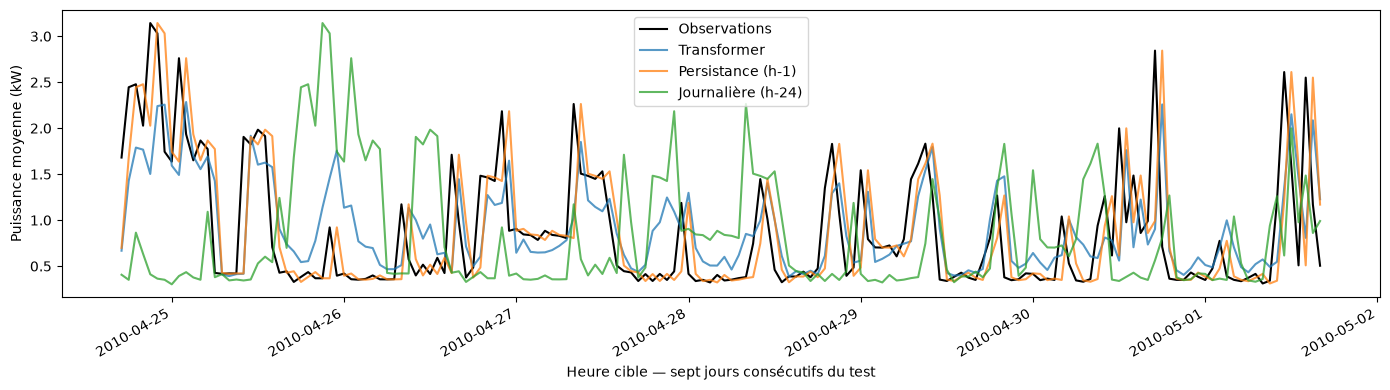

In [5]:
with torch.no_grad():
    predictions = torch.cat([
        modele(xb.to(device)).cpu() for xb, _ in loaders["test"]
    ]).numpy().ravel() * ecart_type + moyenne
X_test = X[masques["test"]].numpy()
observations = y[masques["test"]].numpy().ravel() * ecart_type + moyenne
references = {
    "Transformer": predictions,
    "Persistance (h-1)": X_test[:, -1, 0] * ecart_type + moyenne,
    "Journalière (h-24)": X_test[:, 0, 0] * ecart_type + moyenne,
}
scores = {}
print(f"{'Modèle':24s} {'MAE (kW)':>12s} {'RMSE (kW)':>12s}")
for nom, previsions in references.items():
    erreur = previsions - observations
    mae = float(np.abs(erreur).mean())
    rmse = float(np.sqrt((erreur ** 2).mean()))
    scores[nom] = (mae, rmse)
    print(f"{nom:24s} {mae:12.4f} {rmse:12.4f}")
for nom in ("Persistance (h-1)", "Journalière (h-24)"):
    meilleure_mae, meilleure_rmse = (
        score < reference for score, reference in zip(scores["Transformer"], scores[nom])
    )
    print(f"Transformer meilleur que {nom} : MAE={meilleure_mae}, RMSE={meilleure_rmse}")

heures_test = indices_cibles[masques["test"]]
debut = next((i for i in range(len(heures_test) - 167)
              if np.all(np.diff(heures_test[i:i + 168]) == 1)), None)
if debut is None:
    raise ValueError("Le test ne contient pas sept jours consécutifs sans fenêtre manquante.")
selection = slice(debut, debut + 168)
dates_test = dates[heures_test[selection]]
assert dates_test[-1] - dates_test[0] == np.timedelta64(167, "h")
plt.figure(figsize=(14, 4))
plt.plot(dates_test, observations[selection], label="Observations", color="black")
for nom, previsions in references.items():
    plt.plot(dates_test, previsions[selection], label=nom, alpha=0.75)
plt.ylabel("Puissance moyenne (kW)")
plt.xlabel("Heure cible — sept jours consécutifs du test")
plt.legend()
plt.gcf().autofmt_xdate()
plt.tight_layout()
plt.show()

## 5. Réponses aux questions

**R?sultat enregistr? :** le Transformer am?liore les deux r?f?rences sur ce test, en MAE et en RMSE (0,3480 kW et 0,4926 kW). Ce r?sultat concerne uniquement cette ex?cution et ce d?coupage.

1. **Le Transformer bat-il les références ?** Le tableau et les comparaisons ci-dessus
   répondent séparément pour la MAE et la RMSE sur ce test. Une amélioration n'est
   pas garantie : la persistance est difficile à battre lorsque deux heures se ressemblent.
   Un seul découpage et une seule graine ne suffisent pas pour conclure à une supériorité générale.
2. **Fenêtre de 168 heures :** elle peut apporter une information hebdomadaire, mais
   augmente le coût de l'attention et élimine davantage de fenêtres autour des données
   manquantes. Il faudrait réentraîner avec des positions adaptées et choisir la fenêtre
   sur la validation, puis comparer sur les mêmes heures de test. Ce gain reste à mesurer.
3. **Heure et jour de semaine :** ces variables connues à l'avance représentent les
   habitudes quotidiennes et hebdomadaires. On peut ajouter des embeddings ou des
   encodages cycliques sinus/cosinus pour aider le modèle à distinguer ces situations.
4. **Normaliser seulement sur l'entraînement :** utiliser le futur pour calculer les
   statistiques provoquerait une fuite d'information et rendrait le protocole moins réaliste.
5. **Passer des kW aux kWh :** intégrer la puissance sur la durée : pour des mesures
   moyennes par minute, `énergie_horaire = somme(puissance_minute / 60)` en kWh.
   Une heure complètement observée donne numériquement `puissance_moyenne × 1 h`.
   Avec 45 à 59 minutes observées, la somme brute ne couvre qu'une partie de l'heure :
   exiger 60 mesures pour une énergie horaire complète, ou documenter explicitement
   une imputation/estimation des minutes manquantes. Adapter ensuite la cible et les unités.